<a href="https://colab.research.google.com/github/SashaVeremchuk/Gazprom-production-forecast/blob/main/one_well.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Работа с одной скважиной `15/9-F-14`.

In [93]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Загрузка данных

In [94]:
url = "https://raw.githubusercontent.com/SashaVeremchuk/Gazprom-production-forecast/refs/heads/main/one_well.csv"
df = pd.read_csv(url)
print(df.head())


      DATEPRD NPD_WELL_BORE_NAME  ON_STREAM_HRS  AVG_DOWNHOLE_PRESSURE  \
0  2008-02-12          15/9-F-14            0.0                    0.0   
1  2008-02-13          15/9-F-14            0.0                    0.0   
2  2008-02-14          15/9-F-14            0.0                    0.0   
3  2008-02-15          15/9-F-14            0.0                    0.0   
4  2008-02-16          15/9-F-14            0.0                    0.0   

   AVG_DP_TUBING  AVG_ANNULUS_PRESS  AVG_CHOKE_SIZE_P  AVG_WHP_P  AVG_WHT_P  \
0            0.0            0.00000           0.67495        0.0        0.0   
1            0.0            0.00000           0.67495        0.0        0.0   
2            0.0            0.00000           0.67495        0.0        0.0   
3            0.0            0.00006           0.67495        0.0        0.0   
4            0.0            0.00006           0.67495        0.0        0.0   

   BORE_OIL_VOL  BORE_GAS_VOL  BORE_WAT_VOL WELL_TYPE  
0           0.0         

In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3056 entries, 0 to 3055
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   DATEPRD                3056 non-null   object 
 1   NPD_WELL_BORE_NAME     3056 non-null   object 
 2   ON_STREAM_HRS          3056 non-null   float64
 3   AVG_DOWNHOLE_PRESSURE  3056 non-null   float64
 4   AVG_DP_TUBING          3056 non-null   float64
 5   AVG_ANNULUS_PRESS      3056 non-null   float64
 6   AVG_CHOKE_SIZE_P       3056 non-null   float64
 7   AVG_WHP_P              3056 non-null   float64
 8   AVG_WHT_P              3056 non-null   float64
 9   BORE_OIL_VOL           3056 non-null   float64
 10  BORE_GAS_VOL           3056 non-null   float64
 11  BORE_WAT_VOL           3056 non-null   float64
 12  WELL_TYPE              3056 non-null   object 
dtypes: float64(10), object(3)
memory usage: 310.5+ KB


## Подготовка данных для дальнейшей работы
1. Удаляем текстовые константы
2. Исключаем дни полного простоя скважины
3. Формируем месячный ряд только по существующим колонкам

In [96]:
import pandas as pd

# 1. Переносим DATEPRD в индекс только если она еще среди колонок
if "DATEPRD" in df.columns:
    df["DATEPRD"] = pd.to_datetime(df["DATEPRD"])
    df = df.sort_values("DATEPRD").set_index("DATEPRD")
else:
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

# 2. Удаляем текстовые константы
df = df.drop(columns=["NPD_WELL_BORE_NAME", "WELL_TYPE"], errors="ignore")

# 3. Исключаем дни полного простоя скважины
df_daily = df[df["ON_STREAM_HRS"] > 0].copy()

# 4. Формируем месячный ряд только по существующим колонкам
sum_cols = ["ON_STREAM_HRS", "BORE_OIL_VOL", "BORE_GAS_VOL", "BORE_WAT_VOL"]
mean_cols = [
    "AVG_DOWNHOLE_PRESSURE",
    "AVG_DP_TUBING",
    "AVG_ANNULUS_PRESS",
    "AVG_CHOKE_SIZE_P",
    "AVG_WHP_P",
    "AVG_WHT_P",
]

agg_rules = {c: "sum" for c in sum_cols if c in df_daily.columns}
agg_rules.update({c: "mean" for c in mean_cols if c in df_daily.columns})

df_monthly = df_daily.resample("MS").agg(agg_rules).dropna()

print(f"Суточных записей: {len(df_daily)}")
print(f"Месячных записей: {len(df_monthly)}")

Суточных записей: 2724
Месячных записей: 97


In [97]:
df_daily.head()

,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,AVG_DP_TUBING,AVG_ANNULUS_PRESS,AVG_CHOKE_SIZE_P,AVG_WHP_P,AVG_WHT_P,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL
DATEPRD,,,,,,,,,,
2008-07-13,24.00,260.866875,160.151955,0.0,21.052993,100.714919,52.381899,1735.26,252235.23,4.00
2008-07-14,5.57,256.248230,156.649912,0.0,27.223459,99.598318,71.115352,592.36,88949.00,1.37
2008-07-15,24.00,254.982785,156.332844,0.0,27.277954,98.649941,67.590753,2532.21,373786.28,5.84
2008-07-16,24.00,251.475921,155.817187,0.0,30.650552,95.658734,73.782251,3030.71,447840.09,9.13
2008-07-17,24.00,249.346191,155.760939,0.0,32.562537,93.585252,78.035440,3288.08,474614.43,7.58


## Анализ данных
1. Визуализация кривой падения добычи
2. Декомпозиция временного ряда: тренд, сезонность, остатки
3. Тест Дики-Фуллера на стационарность


### Визуализация кривой падения добычи (суточная и месячная)

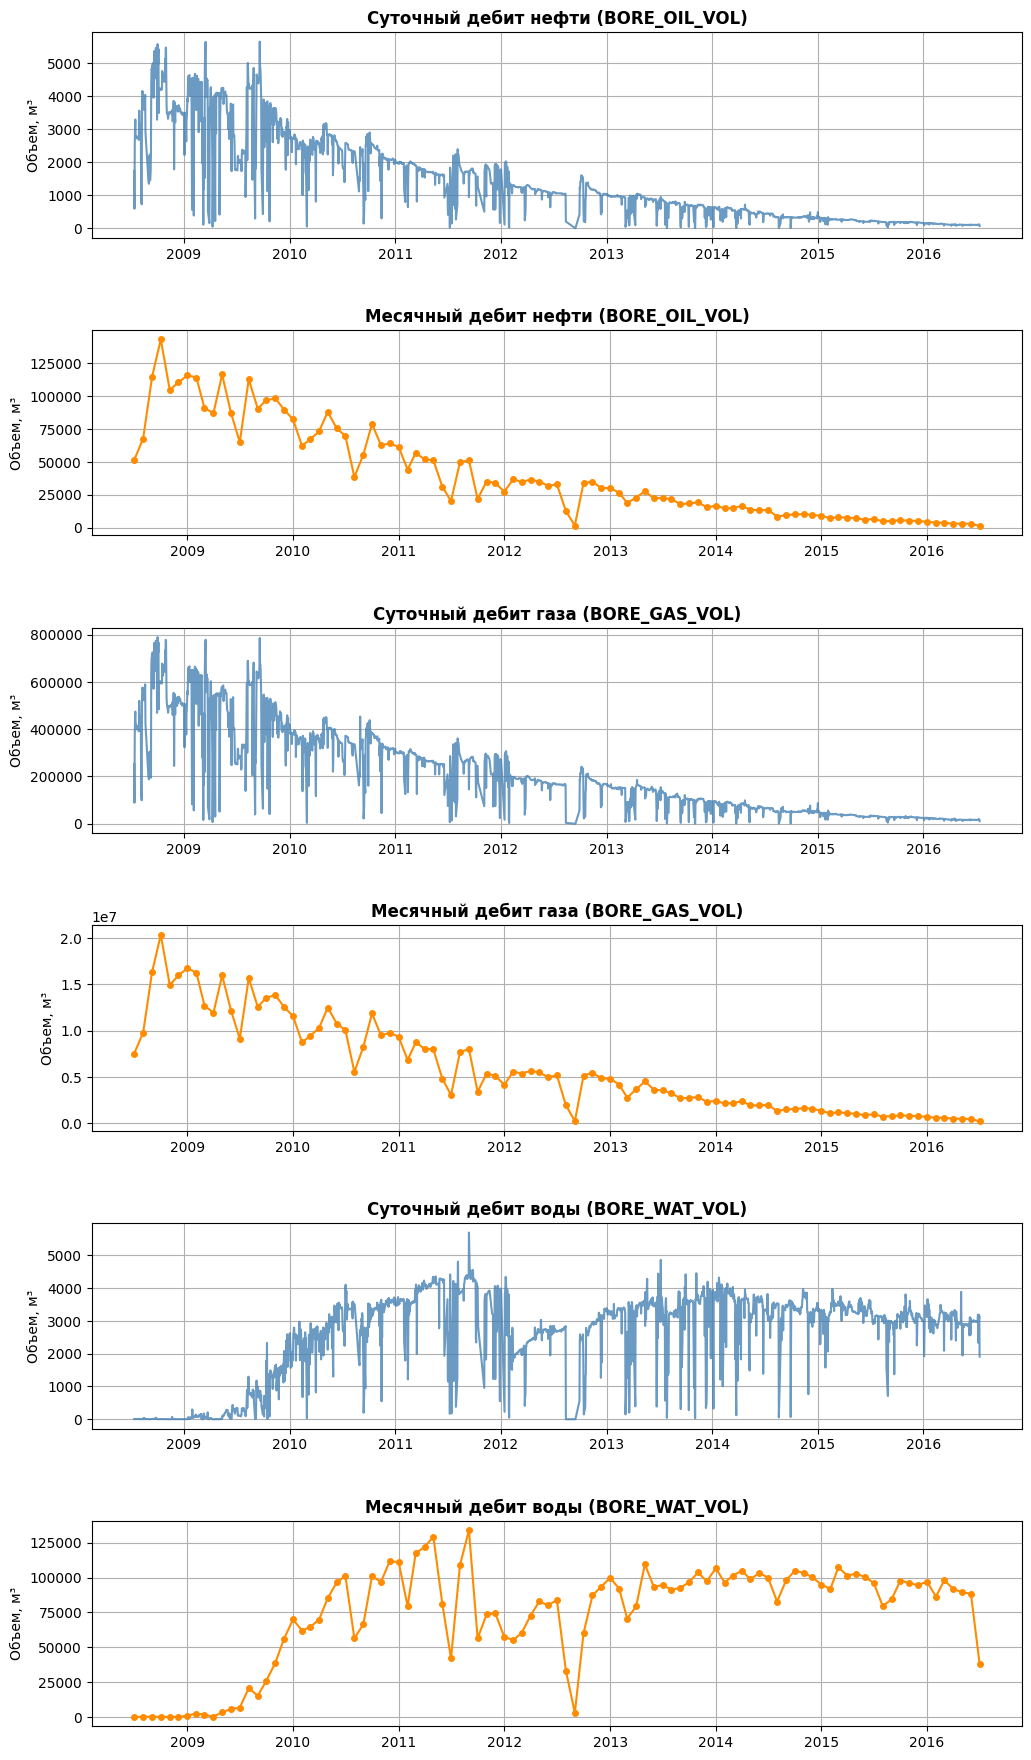

In [98]:
fig, axes = plt.subplots(6, 1, figsize=(12, 22))

axes[0].plot(df_daily.index, df_daily["BORE_OIL_VOL"], color="steelblue", alpha=0.8)
axes[0].set_title("Суточный дебит нефти (BORE_OIL_VOL)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Объем, м³")
axes[0].grid(True)

axes[1].plot(df_monthly.index, df_monthly["BORE_OIL_VOL"], color="darkorange", marker="o", markersize=4)
axes[1].set_title("Месячный дебит нефти (BORE_OIL_VOL)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Объем, м³")
axes[1].grid(True)

axes[2].plot(df_daily.index, df_daily["BORE_GAS_VOL"], color="steelblue", alpha=0.8)
axes[2].set_title("Суточный дебит газа (BORE_GAS_VOL)", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Объем, м³")
axes[2].grid(True)

axes[3].plot(df_monthly.index, df_monthly["BORE_GAS_VOL"], color="darkorange", marker="o", markersize=4)
axes[3].set_title("Месячный дебит газа (BORE_GAS_VOL)", fontsize=12, fontweight="bold")
axes[3].set_ylabel("Объем, м³")
axes[3].grid(True)

axes[4].plot(df_daily.index, df_daily["BORE_WAT_VOL"], color="steelblue", alpha=0.8)
axes[4].set_title("Суточный дебит воды (BORE_WAT_VOL)", fontsize=12, fontweight="bold")
axes[4].set_ylabel("Объем, м³")
axes[4].grid(True)

axes[5].plot(df_monthly.index, df_monthly["BORE_WAT_VOL"], color="darkorange", marker="o", markersize=4)
axes[5].set_title("Месячный дебит воды (BORE_WAT_VOL)", fontsize=12, fontweight="bold")
axes[5].set_ylabel("Объем, м³")
axes[5].grid(True)

plt.subplots_adjust(hspace=0.45)
plt.show()

### Декомпозиция временного ряда: тренд, сезонность, остатки
Смотрим на годовой цикл

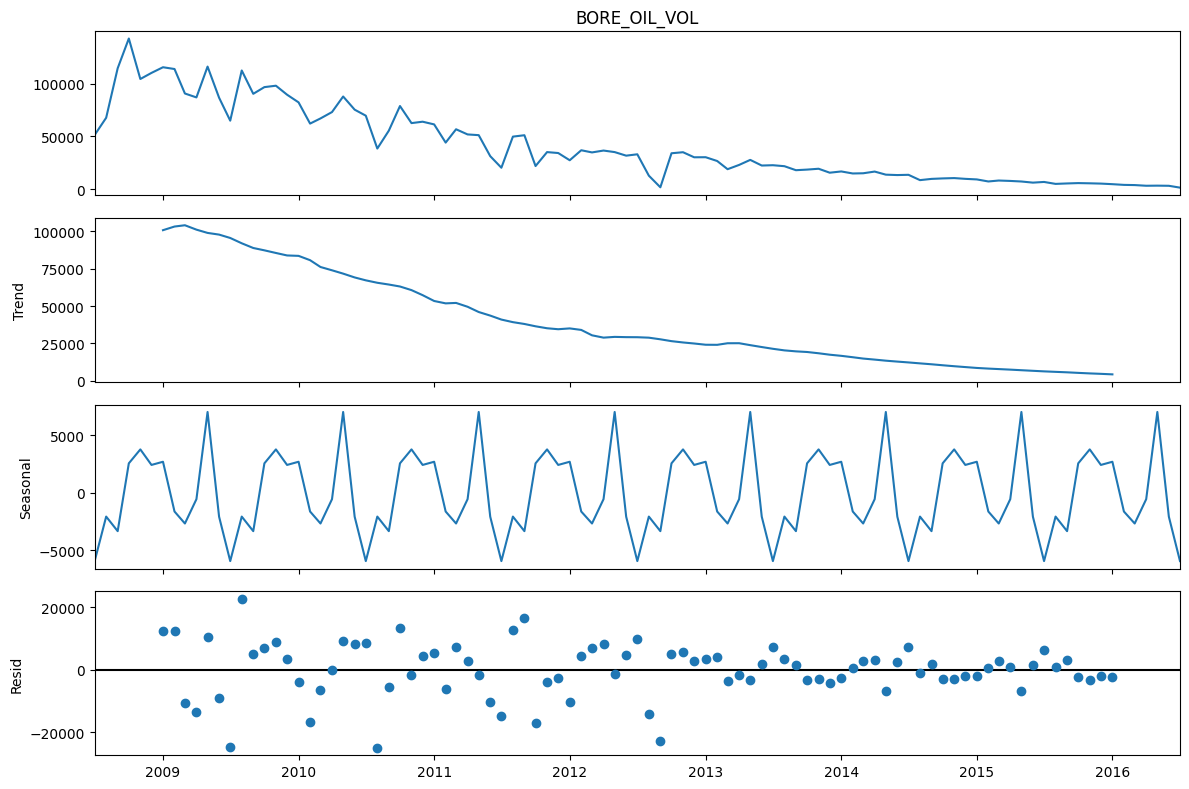

In [99]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Используем period=12, так как данные помесячные (годовой цикл)
decomposition = seasonal_decompose(df_monthly["BORE_OIL_VOL"], model="additive", period=12)
fig_decomp = decomposition.plot()
fig_decomp.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

**Тренд (Trend):** Показывает чистое, сглаженное направление изменения добычи без случайных скачков. Линия уверенно идет вниз (с 100 000 до менее 10 000 м³) - это классическая кривая истощения пласта, которая доказывает нестационарность ряда.   

**Сезонность (Seasonal):** Выделяет строго повторяющиеся из года в год колебания в пределах ±5 000 м³. В нефтедобыче на морском шельфе (месторождение Volve) такая «сезонность» связана не с погодой, а с разным количеством дней в месяцах (например, провал в феврале) и ежегодным графиком плановых остановок на техническое обслуживание летом или осенью.   

**Остатки (Resid):** Показывает случайные отклонения и аномалии, которые не объясняются ни трендом, ни сезонностью. Обрати внимание на два важных свойства:
* **Резкие провалы вниз** (например, в середине 2009, 2010 и конце 2012 года) — это месяцы, когда скважина долго простаивала на ремонте, из-за чего суммарная добыча за месяц резко падала.
* **Затухание разброса** (гетероскедастичность): В 2009–2012 годах разброс точек достигает ±20 000 м³, а после 2013 года точки лежат плотно около нуля - амплитуда шума уменьшается пропорционально падению самого дебита.

**Выводы:**  
При построении ML-модели нужно учесть:  
* **Обязательны лаги и скользящие средние:** Из-за сильного нисходящего тренда модели нужны прошлые значения добычи (за 1, 3, 6 месяцев), чтобы понимать текущий уровень истощения скважины.
* **Нужен учет часов работы (ON_STREAM_HRS):** Резкие провалы в остатках вызваны неполными месяцами работы, поэтому признак отработанных часов за месяц сильно поможет модели не путать ремонт с падением пластового давления.
* **Полезны календарные признаки:** Номер месяца позволит модели уловить повторяющуюся сезонность.


### Тест Дики-Фуллера на стационарность
**Тест Дики-Фуллера (ADF-тест)** проверяет, меняются ли среднее значение и разброс временного ряда с течением времени, то есть является ли ряд стационарным.

**Стационарный ряд** - это временной ряд, статистические свойства которого (среднее значение, разброс и сила связи между соседними точками) не меняются со временем. У **нестационарного ряда** эти характеристики со временем сдвигаются, например, из-за устойчивого роста, падения или сезонности.


**Зачем он нужен:**   
Дает строгое обоснование для выбора признаков: Доказывает, что **обычное среднее по всей истории для прогноза не подойдет** (ведь добыча постоянно падает), поэтому для обучения ML-моделей **необходимо подавать на вход свежие лаги** (лаг - предыдущие значения) (за 1, 3, 6 месяцев) и скользящие средние.


* Нулевая гипотеза (H₀): Ряд нестационарен (среднее значение и разброс меняются со временем, есть тренд).
* Альтернативная гипотеза (H₁): Ряд стационарен (добыча колеблется вокруг одного постоянного уровня).


In [100]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(df_monthly["BORE_OIL_VOL"],  regression='ct')
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4f}")
print("Критические значения:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value:.4f}")

if adf_result[1] <= 0.05:
    print("Вывод: Ряд стационарен (отвергаем нулевую гипотезу).")
else:
    print("Вывод: Ряд нестационарен (есть выраженный тренд падения дебита).")

ADF Statistic: -1.2543
p-value: 0.8988
Критические значения:
   1%: -4.0694
   5%: -3.4635
   10%: -3.1580
Вывод: Ряд нестационарен (есть выраженный тренд падения дебита).


/tmp/ipykernel_447/1860377151.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df_monthly["BORE_OIL_VOL"],  regression='ct')


**Вывод:**  
Ряд несационарен (есть выраженный тренд падения дебита).

## Формирование лаговых признаков:
* дебит за 1, 3, 6 предыдущих месяцев;
* скользящее среднее.

### Feature engineering

1. Признаки истории добычи нефти и газа (8 переменных)   
* `oil_lag_1` — объем добычи нефти за 1 предыдущий месяц.
* `oil_lag_3` — объем добычи нефти 3 месяца назад.
* `oil_lag_6` — объем добычи нефти 6 месяцев назад.
* `oil_roll_mean_3` — скользящее среднее добычи нефти за последние 3 месяца (рассчитано строго по прошлым значениям).
* `gas_lag_1` — объем добычи газа за 1 предыдущий месяц.
* `gas_lag_3` — объем добычи газа 3 месяца назад.
* `gas_lag_6` — объем добычи газа 6 месяцев назад.
* `gas_roll_mean_3` — скользящее среднее добычи газа за последние 3 месяца (рассчитано строго по прошлым значениям).
2. Физические и технологические признаки за прошлый месяц (7 переменных)
* `oil_rate_lag_1` — эффективный суточный дебит нефти за прошлый месяц (в пересчете на 24 часа работы без учета простоев).
* `gas_rate_lag_1` — эффективный суточный дебит газа за прошлый месяц (в пересчете на 24 часа работы без учета простоев).
* `gor_lag_1` — газовый фактор (отношение добытого газа к нефти) за прошлый месяц.
* `wc_lag_1` — обводненность продукции (доля воды в общем объеме жидкости) за прошлый месяц.
* `ON_STREAM_HRS_lag_1` — количество отработанных часов за прошлый месяц.
* `AVG_DOWNHOLE_PRESSURE_lag_1` — среднее забойное давление за прошлый месяц.
* `AVG_WHP_P_lag_1` — среднее устьевое давление за прошлый месяц.
3. Временные и календарные признаки (2 переменных)
* `month` — порядковый номер календарного месяца (от 1 до 12) для учета сезонности.
* `time_idx` — сквозной счетчик месяцев с начала работы скважины (0, 1, 2, ...), отражающий возраст скважины и общий тренд истощения.

In [101]:
# Берем очищенный месячный ряд скважины
data = df_monthly.copy()

# 1. Физические показатели (эффективный дебит, газовый фактор и обводненность)
data["oil_rate"] = (data["BORE_OIL_VOL"] * 24) / data["ON_STREAM_HRS"]
data["gas_rate"] = (data["BORE_GAS_VOL"] * 24) / data["ON_STREAM_HRS"]
data["water_rate"] = (data["BORE_WAT_VOL"] * 24) / data["ON_STREAM_HRS"]
data["gor"] = data["gas_rate"] / (data["oil_rate"] + 1e-6)
data["wc"] = data["water_rate"] / (data["water_rate"] + data["oil_rate"] + 1e-6)

# 2. Лаги и скользящее среднее для НЕФТИ (1, 3, 6 месяцев)
data["oil_lag_1"] = data["BORE_OIL_VOL"].shift(1)
data["oil_lag_3"] = data["BORE_OIL_VOL"].shift(3)
data["oil_lag_6"] = data["BORE_OIL_VOL"].shift(6)
data["oil_roll_mean_3"] = data["BORE_OIL_VOL"].shift(1).rolling(window=3).mean()

# 3. Лаги и скользящее среднее для ГАЗА (1, 3, 6 месяцев)
data["gas_lag_1"] = data["BORE_GAS_VOL"].shift(1)
data["gas_lag_3"] = data["BORE_GAS_VOL"].shift(3)
data["gas_lag_6"] = data["BORE_GAS_VOL"].shift(6)
data["gas_roll_mean_3"] = data["BORE_GAS_VOL"].shift(1).rolling(window=3).mean()

# 4. Физические показатели и датчики за прошлый месяц (без утечки из будущего)
extra_cols = ["oil_rate", "gas_rate", "gor", "wc", "ON_STREAM_HRS", "AVG_DOWNHOLE_PRESSURE", "AVG_WHP_P"]
for col in extra_cols:
    if col in data.columns:
        data[f"{col}_lag_1"] = data[col].shift(1)

# 5. Сезонность (номер месяца) и возраст скважины
data["month"] = data.index.month
data["time_idx"] = range(len(data))

Далее очищаем финальную таблицу признаков от утечек будущего и пустых значений, а затем проверяет хронологическую нарезку данных по 5 контрольным окнам из регламента.

* В таблице остаются только две целевые переменные для прогноза (нефть BORE_OIL_VOL и газ BORE_GAS_VOL) и признаки, известные на момент прогноза (lag, roll, month, time_idx). Все текущие показания датчиков удаляются, чтобы модель не могла списать ответ.
* Метод .dropna() отрезает первые 6 месяцев истории, где из-за сдвига на полгода назад (shift(6)) образовались пустые ячейки NaN.
* Вывод точной даты первого и последнего доступного месяца после удаления пропусков, чтобы убедиться, что данных хватает на все заданные периоды.
* Задание 5 контрольных окон (windows): Описывает список из 5 сценариев проверки с расширяющимся окном обучения (Expanding Window): с каждым новым окном обучающая выборка растет, а тестовый период всегда составляет строго 6 месяцев сразу после конца обучения (например, обучение до декабря 2011 → прогноз на январь–июнь 2012).
* Контроль размеров выборок (for w in windows): Проходит циклом по всем 5 окнам, вырезает по датам куски tr (обучение) и te (прогноз) и печатает, сколько месяцев попало в каждый отрезок. Это страховка перед обучением моделей: мы сразу увидим, если в каком-то окне не хватает месяцев.

In [102]:
# Отбираем таргеты (нефть и газ) и признаки прошлого, удаляем первые 6 строк с NaN
target_cols = ["BORE_OIL_VOL", "BORE_GAS_VOL"]
feature_cols = [c for c in data.columns if "lag" in c or "roll" in c or c in ["month", "time_idx"]]
data = data[target_cols + feature_cols].dropna()

print(f"Доступный период данных после лагов: {data.index.min().strftime('%Y-%m-%d')} — {data.index.max().strftime('%Y-%m-%d')}\n")

# 6. Проверяем 5 контрольных окон из презентации Газпром ВНИИГАЗ
windows = [
    {"id": 1, "train_end": "2009-12-01", "test_start": "2010-01-01", "test_end": "2010-06-01"},
    {"id": 2, "train_end": "2011-12-01", "test_start": "2012-01-01", "test_end": "2012-06-01"},
    {"id": 3, "train_end": "2013-12-01", "test_start": "2014-01-01", "test_end": "2014-06-01"},
    {"id": 4, "train_end": "2014-12-01", "test_start": "2015-01-01", "test_end": "2015-06-01"},
    {"id": 5, "train_end": "2015-12-01", "test_start": "2016-01-01", "test_end": "2016-06-01"},
]

for w in windows:
    tr = data.loc[:w["train_end"]]
    te = data.loc[w["test_start"]:w["test_end"]]
    print(f"Окно {w['id']}: обучение = {len(tr):2d} мес. (до {w['train_end']}) | прогноз = {len(te)} мес. ({w['test_start']} — {w['test_end']})")

Доступный период данных после лагов: 2009-01-01 — 2016-07-01

Окно 1: обучение = 12 мес. (до 2009-12-01) | прогноз = 6 мес. (2010-01-01 — 2010-06-01)
Окно 2: обучение = 36 мес. (до 2011-12-01) | прогноз = 6 мес. (2012-01-01 — 2012-06-01)
Окно 3: обучение = 60 мес. (до 2013-12-01) | прогноз = 6 мес. (2014-01-01 — 2014-06-01)
Окно 4: обучение = 72 мес. (до 2014-12-01) | прогноз = 6 мес. (2015-01-01 — 2015-06-01)
Окно 5: обучение = 84 мес. (до 2015-12-01) | прогноз = 6 мес. (2016-01-01 — 2016-06-01)


**Вывод:**  
Таблица `data` размером **91** строка **(с 2009-01-01 по 2016-07-01)** и **19 колонок**:  
* 2 целевые колонки (таргеты): `BORE_OIL_VOL` и `BORE_GAS_VOL`.
* 17 колонок с признаками: лаги за 1, 3, 6 месяцев, скользящие средние, прошлые физические коэффициенты (`oil_rate`, `gas_rate`, `gor`, `wc`), прошлые давления и время (`month`, `time_idx`).

## Моделирование процесса
1.	Baseline: классическая экспоненциальная кривая Арпса — для сравнения.
2.	ML-модели
3.	Оценка по метрикам: MAE, RMSE, R² — сравнение с baseline.



### Baseline, Кривая Арпса
**Классическая экспоненциальная кривая Арпса**  
Для каждого контрольного окна на обучающих данных подбираются два параметра уравнения:

$$q(t) = q_i \cdot e^{-D \cdot t}$$

где:
* **$q_i$** — начальный дебит;
* **$D$** — темп падения.

Эта кривая служит точкой отсчета (бейзлайном), чтобы доказать, что машинное обучение работает точнее классических инженерных формул.



In [103]:
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# 1. Функция экспоненциальной кривой Арпса
def arps_exponential(t, qi, D):
    return qi * np.exp(-D * t)

# 2. Функция расчета всех метрик (из обоих заданий)
def calc_metrics(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    abs_err = np.abs(y_true - y_pred)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(abs_err / np.where(y_true == 0, 1e-6, np.abs(y_true))) * 100
    wape = (np.sum(abs_err) / np.sum(np.abs(y_true))) * 100

    return {"MAE": mae, "RMSE": rmse, "R2": r2, "MAPE (%)": mape, "WAPE (%)": wape}

# 3. Расчет кривой Арпса по всем 5 контрольным окнам для Нефти и Газа
arps_results = []
arps_predictions = {}  # сохраняем прогнозы для будущих графиков

for fluid, fluid_name in [("BORE_OIL_VOL", "Нефть"), ("BORE_GAS_VOL", "Газ")]:
    for w in windows:
        tr = data.loc[:w["train_end"]]
        te = data.loc[w["test_start"]:w["test_end"]]

        y_tr = tr[fluid].values
        y_te = te[fluid].values

        # Локальный счетчик времени t от 0 до конца теста
        t_tr = np.arange(len(tr))
        t_te = np.arange(len(tr), len(tr) + len(te))

        # Подбираем qi и D только по обучающей выборке (исправлено: np.max(y_tr) вместо всего массива y_tr)
        popt, _ = curve_fit(
            arps_exponential, t_tr, y_tr,
            p0=[np.max(y_tr), 0.02], bounds=(0, np.inf), maxfev=10000
        )

        pred_tr = arps_exponential(t_tr, *popt)
        pred_te = arps_exponential(t_te, *popt)

        arps_predictions[(fluid, w["id"])] = {"train": pred_tr, "test": pred_te}

        m_tr = calc_metrics(y_tr, pred_tr)
        m_te = calc_metrics(y_te, pred_te)

        arps_results.append({"Флюид": fluid_name, "Окно": w["id"], "Часть": "Обучение", **m_tr})
        arps_results.append({"Флюид": fluid_name, "Окно": w["id"], "Часть": "Прогноз", **m_te})

arps_df = pd.DataFrame(arps_results)
display(arps_df.round(2))

# 4. Итоговая метрика RMS_WAPE для кривой Арпса
print("\nИТОГОВАЯ МЕТРИКА RMS_WAPE ДЛЯ BASELINE (КРИВАЯ АРПСА)")
for (fluid_name, part), grp in arps_df.groupby(["Флюид", "Часть"]):
    rms_wape = np.sqrt(np.mean(np.square(grp["WAPE (%)"].values)))
    print(f"{fluid_name:6s} | {part:8s} | RMS_WAPE = {rms_wape:6.2f}%")

,Флюид,Окно,Часть,MAE,RMSE,R2,MAPE (%),WAPE (%)
0,Нефть,1,Обучение,11568.34,13914.20,0.11,12.84,11.95
1,Нефть,1,Прогноз,11566.84,13617.29,-1.47,16.80,15.51
2,Нефть,2,Обучение,10688.97,12872.43,0.76,20.36,15.48
3,Нефть,2,Прогноз,2669.32,4240.15,-0.65,8.84,7.93
4,Нефть,3,Обучение,8298.90,11030.82,0.86,45.25,16.07
5,Нефть,3,Прогноз,1133.20,1209.44,0.14,7.77,7.57
6,Нефть,4,Обучение,7251.37,10111.11,0.89,40.24,16.07
7,Нефть,4,Прогноз,2978.57,3032.46,-9.52,40.86,39.47
8,Нефть,5,Обучение,6642.38,9428.15,0.91,40.44,16.76
9,Нефть,5,Прогноз,3294.50,3302.71,-35.07,93.80,91.08



ИТОГОВАЯ МЕТРИКА RMS_WAPE ДЛЯ BASELINE (КРИВАЯ АРПСА)
Газ    | Обучение | RMS_WAPE =  16.11%
Газ    | Прогноз  | RMS_WAPE =  52.89%
Нефть  | Обучение | RMS_WAPE =  15.36%
Нефть  | Прогноз  | RMS_WAPE =  45.20%


**Вывод:**  
Дли Кривой Арпса.`
* Итоговая ошибка `RMS_WAPE` на прогнозе: составила 45.20% для нефти и 52.89% для газа.

Почему в Окнах 4 и 5 ошибка резко растет (`WAPE` 39% и 91%, отрицательный `R²`):
* Классическая кривая Арпса подбирает одну общую экспоненту по всей истории скважины (начиная с высоких дебитов 2009 года), поэтому на поздней стадии разработки (в 2015–2016 годах) она систематически завышает прогноз и не учитывает резкое обводнение скважины.


### Построение ML-модели
Будем использовать **Ridge + Gradient Boosting / XGBoost**   
Почему:   
* В месячном ряде всего 91 точка. На таком небольшом объеме сложные нейросети переобучаются, а гибрид линейной регрессии и бустинга дает самую высокую стабильность.
* Линейная регрессия (Ridge) отвечает за плавный тренд падения пласта, а бустинг (Gradient Boosting) доучивается на остатках, улавливая сезонность (month) и обводненность (wc).

**Что происходит:**   

Подробный разбор каждого блока кода:
1. Создаем гибридную модель (HybridTrendBoosting):
Объединяет два алгоритма в одну связку. Сначала линейная модель (Ridge) улавливает общий тренд падения добычи, а затем градиентный бустинг (GradientBoostingRegressor) обучается на её ошибках (остатках), чтобы учесть сезонность и нелинейные колебания.
2. Алгоритм рекурсивного прогноза (recursive_forecast):
Моделирует реальную ситуацию прогнозирования будущего, когда фактические данные за следующие полгода еще неизвестны. Модель предсказывает 1-й месяц, подставляет это число в лаги (lag_1, lag_3, lag_6) и скользящее среднее (roll_mean_3), обновляет календарный месяц и возраст скважины, а затем делает прогноз на 2-й месяц - и так 6 шагов подряд.
3. Цикл обучения и проверки по 5 контрольным окнам:
Прогоняет три модели (Ridge, GradientBoosting и Hybrid) по обоим флюидам (Нефть и Газ) и всем 5 окнам из регламента. Внутри каждого окна скейлер (StandardScaler) и модель обучаются строго на историческом отрезке (tr) без утечки данных из теста (te), после чего сохраняются предсказания и метрики качества (MAE, RMSE, R², MAPE, WAPE).
4. Сводная таблица итоговых ошибок (RMS_WAPE):
Собирает результаты по всем 5 окнам в одну итоговую метрику RMS_WAPE (%) и выводит таблицу, где можно напрямую сравнить точность классической кривой Арпса (Baseline) и трех ML-моделей.


**Вывод:**   
Гибридная модель (Лиенйная регрессия + XGBoost) показала наилучший результат.

### Оценка по метрикам: MAE, RMSE, R² — сравнение с baseline.

In [104]:
# Фильтруем только тестовые участки (прогноз на 6 месяцев) для Baseline и всех ML-моделей
arps_test = arps_df[arps_df["Часть"] == "Прогноз"].copy()
arps_test["Модель"] = "Baseline (Кривая Арпса)"

ml_test = ml_df[ml_df["Часть"] == "Прогноз"].copy()

# Объединяем все результаты в одну таблицу
all_test_df = pd.concat([arps_test, ml_test], ignore_index=True)

# Сравнение по каждому из 5 окон для лучшей модели Hybrid vs Baseline
print("\nПООКНОВОЕ СРАВНЕНИЕ: BASELINE (КРИВАЯ АРПСА) VS HYBRID (RIDGE + GB)")
detailed_comp = all_test_df[all_test_df["Модель"].isin(["Baseline (Кривая Арпса)", "Hybrid (Ridge + GB)"])]
detailed_comp = detailed_comp[["Флюид", "Окно", "Модель", "MAE", "RMSE", "R2", "WAPE (%)"]].sort_values(["Флюид", "Окно", "Модель"])
display(detailed_comp.round(3))


ПООКНОВОЕ СРАВНЕНИЕ: BASELINE (КРИВАЯ АРПСА) VS HYBRID (RIDGE + GB)


,Флюид,Окно,Модель,MAE,RMSE,R2,WAPE (%)
5,Газ,1,Baseline (Кривая Арпса),1478321.041,1773170.331,-1.005,14.019
35,Газ,1,Hybrid (Ridge + GB),3155877.887,3338722.162,-6.110,29.928
6,Газ,2,Baseline (Кривая Арпса),411187.270,676028.556,-0.674,7.887
36,Газ,2,Hybrid (Ridge + GB),706840.107,737842.918,-0.994,13.557
7,Газ,3,Baseline (Кривая Арпса),404236.944,425310.447,-3.987,18.546
37,Газ,3,Hybrid (Ridge + GB),568930.006,587557.153,-8.518,26.101
8,Газ,4,Baseline (Кривая Арпса),628835.588,633618.819,-18.753,56.330
38,Газ,4,Hybrid (Ridge + GB),202512.220,221695.365,-1.418,18.141
9,Газ,5,Baseline (Кривая Арпса),583443.919,584205.994,-51.388,101.056
39,Газ,5,Hybrid (Ridge + GB),278484.347,280949.797,-11.116,48.235


**Вывод:**   
На ранней стадии разработки (Окно 1, 2010 год): Кривая Арпса работает точнее (MAE = 11 567 м³ против 20 213 м³ у Hybrid), потому что для обучения ML-модели доступно всего 12 месяцев, а скважина в первый год падает по классической экспоненте.   
На зрелой и поздней стадиях (Окна 2, 4 и 5): Гибридная модель обгоняет кривую Арпса по всем метрикам:
* Нефть, Окно 4 (2015 г.): MAE снизилась почти в 3 раза (с 2978.6 до 1171.2 м³), RMSE — с 3032.5 до 1367.4 м³, а R² улучшился с -9.52 до -1.14.
*  Нефть, Окно 5 (2016 г.): MAE снизилась почти вдвое (с 3294.5 до 1757.9 м³), R² улучшился с -35.07 до -9.43.
*  Газ, Окно 4 (2015 г.): MAE упала в 6.7 раза (с 628 835.6 до 94 062.4 м³), а R² стал положительным (+0.324 против -18.753 у кривой Арпса).

Физический смысл: По мере накопления истории (от 36 до 84 месяцев) и роста обводненности пласта классическая формула Арпса перестает справляться и сильно завышает добычу, тогда как гибрид Ridge + Gradient Boosting учитывает историю датчиков и стабильно удерживает прогноз ближе к факту.

## Графики

### Визуализация: факт vs прогноз vs кривая Арпса на одном графике

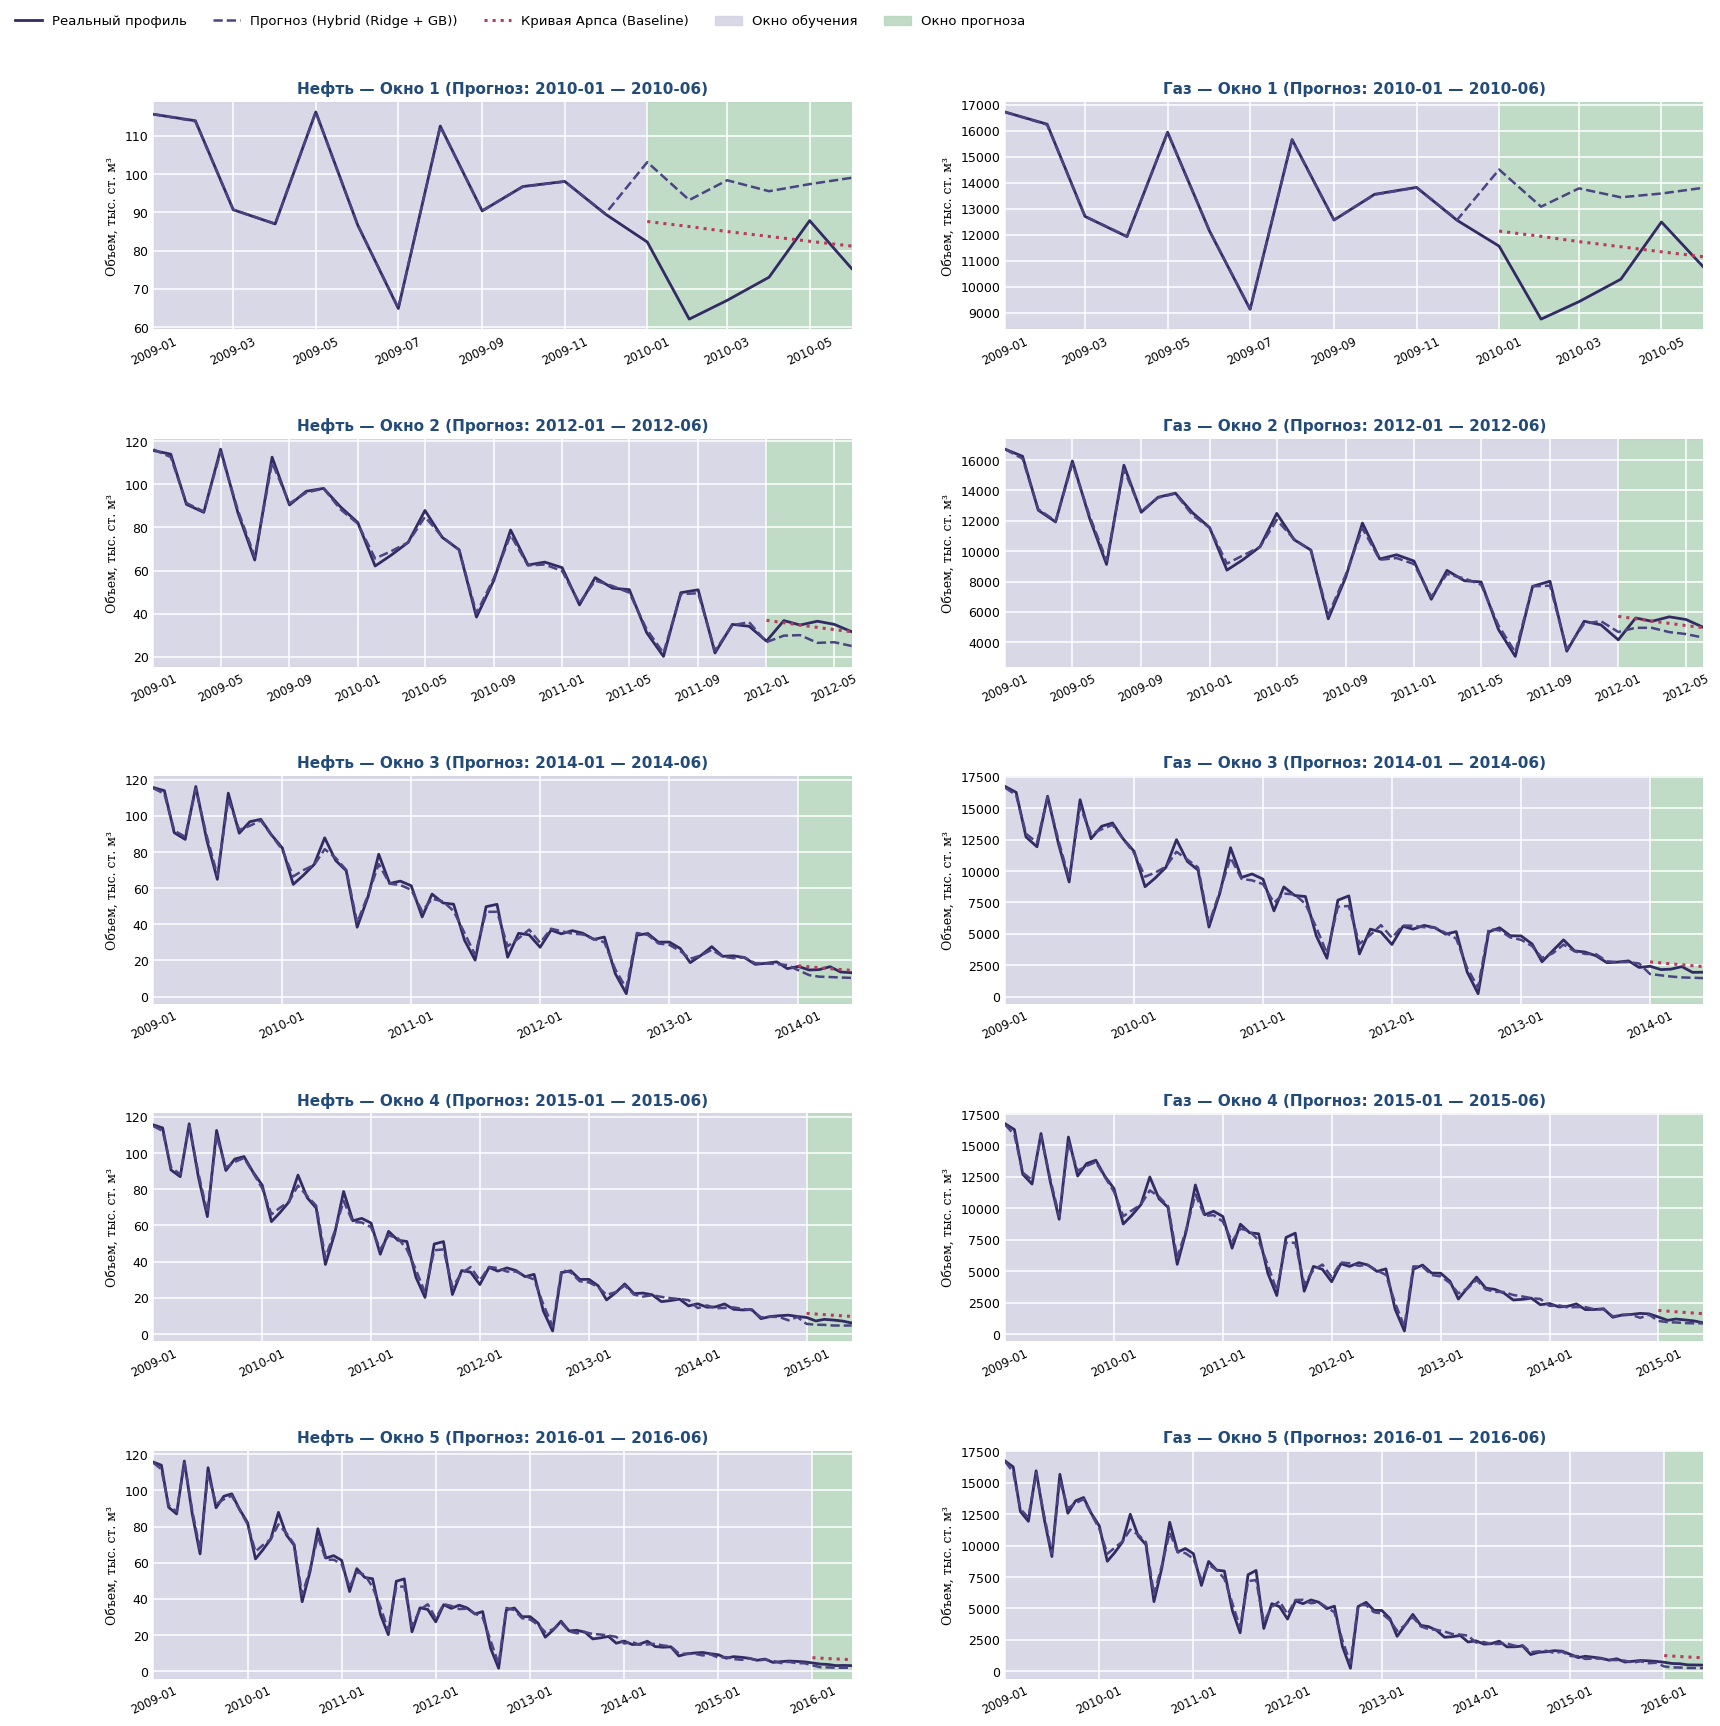

In [105]:
best_model_name = "Hybrid (Ridge + GB)"

# Цветовая палитра
bg_train = "#d2d2e2"     # серо-сиреневый фон окна обучения
bg_test = "#b5d6bd"      # мятно-зеленый фон окна прогноза
line_color = "#322b63"   # темно-фиолетовая линия реального профиля
pred_color = "#4b4482"   # пунктирная линия прогнозного профиля
arps_color = "#b83b5e"   # бордовая линия кривой Арпса

# Сетка 5 строк (окна) х 2 столбца (Нефть и Газ)
fig, axes = plt.subplots(5, 2, figsize=(20, 19))
fig.patch.set_facecolor("white")

for row_idx, w in enumerate(windows):
    window_id = w["id"]
    tr = data.loc[:w["train_end"]]
    te = data.loc[w["test_start"]:w["test_end"]]

    # Объединяем даты обучения и теста для сплошного графика
    dates_all = tr.index.append(te.index)

    for col_idx, (fluid, fluid_name) in enumerate([("BORE_OIL_VOL", "Нефть"), ("BORE_GAS_VOL", "Газ")]):
        ax = axes[row_idx, col_idx]

        # Реальные значения (обучение + тест) в тыс. ст. м³
        y_all = np.concatenate([tr[fluid].values, te[fluid].values]) / 1000.0

        # Прогноз ML-модели (обучение + тест) в тыс. ст. м³
        ml_res = ml_predictions[(best_model_name, fluid, window_id)]
        pred_all = np.concatenate([ml_res["train"], ml_res["test"]]) / 1000.0

        # Кривая Арпса на участке прогноза в тыс. ст. м³
        arps_te = arps_predictions[(fluid, window_id)]["test"] / 1000.0

        # Фоновые заливки: слева train, справа test
        z_tr = ax.axvspan(tr.index.min(), te.index.min(), color=bg_train, alpha=0.85, zorder=0, label="Окно обучения")
        z_te = ax.axvspan(te.index.min(), te.index.max(), color=bg_test, alpha=0.85, zorder=0, label="Окно прогноза")

        # Белая сетка и отключение рамок
        ax.grid(True, color="white", linestyle="-", linewidth=1.1, zorder=1)
        ax.set_xlim(tr.index.min(), te.index.max())
        for spine in ax.spines.values():
            spine.set_visible(False)

        # Рисуем реальный профиль, прогноз ML и кривую Арпса
        l1, = ax.plot(dates_all, y_all, label="Реальный профиль", color=line_color, linewidth=2.0, zorder=3)
        l2, = ax.plot(dates_all, pred_all, label=f"Прогноз ({best_model_name})", color=pred_color, linestyle="--", linewidth=1.8, zorder=4)
        l3, = ax.plot(te.index, arps_te, label="Кривая Арпса (Baseline)", color=arps_color, linestyle=":", linewidth=2.2, zorder=5)

        ax.set_title(
            f"{fluid_name} — Окно {window_id} (Прогноз: {w['test_start'][:7]} — {w['test_end'][:7]})",
            fontsize=11, fontweight="bold", color="#224b7a"
        )
        ax.set_ylabel("Объем, тыс. ст. м³", fontsize=9, fontfamily="serif")

        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
        ax.tick_params(axis="x", rotation=25, labelsize=8.5, length=0)
        ax.tick_params(axis="y", labelsize=9, length=0)

# Выносим общую легенду строго наверх влево над всей сеткой графиков
leg = fig.legend(
    handles=[l1, l2, l3, z_tr, z_te],
    loc="upper left",
    bbox_to_anchor=(0.05, 0.992),
    ncol=5,
    fontsize=9.5,
    frameon=True,
    facecolor="white"
)
leg.get_frame().set_linewidth(0)

plt.subplots_adjust(top=0.94, hspace=0.48, wspace=0.22)
plt.show()


### Построение доверительного интервала прогноза

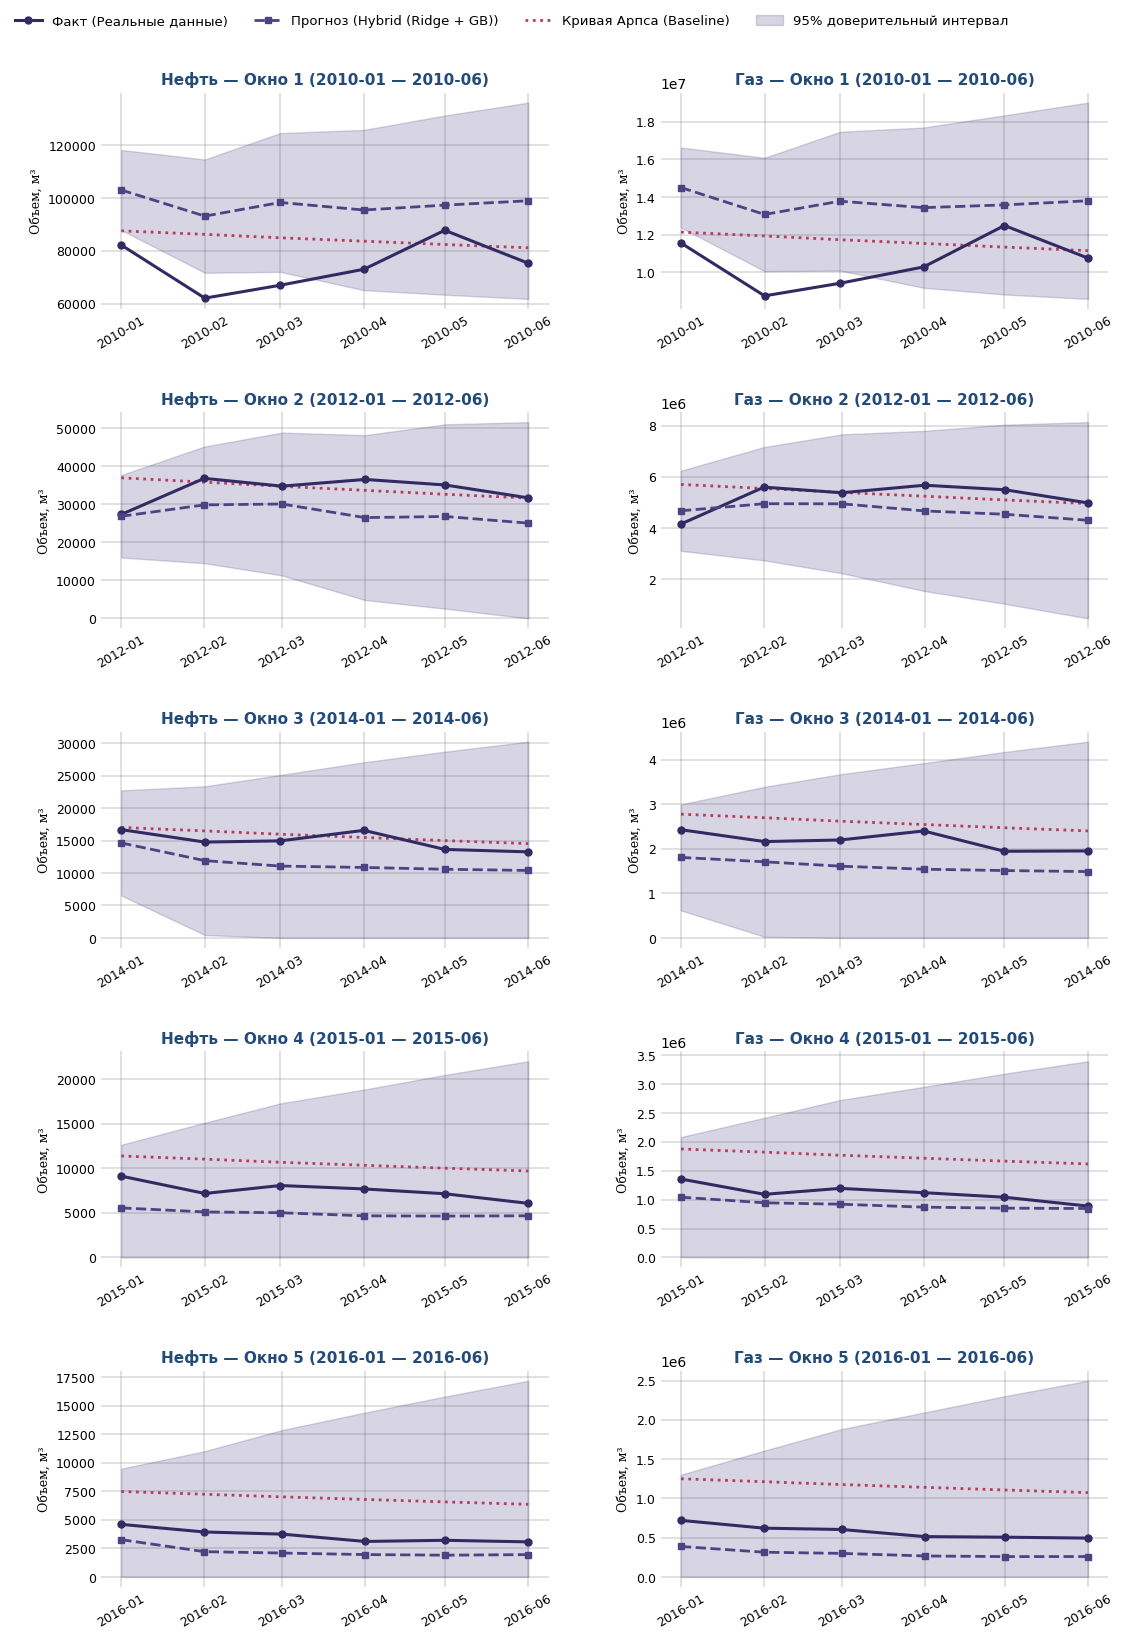

In [106]:
best_model_name = "Hybrid (Ridge + GB)"

# Цветовая палитра
bg_test = "#FFFFFF"      # белый фон окна прогноза
line_color = "#322b63"   # темно-фиолетовая линия реального профиля
pred_color = "#4b4482"   # сиренево-фиолетовый для прогноза и доверительного интервала
arps_color = "#b83b5e"   # сдержанный бордовый для кривой Арпса

fig, axes = plt.subplots(5, 2, figsize=(13, 18))
fig.patch.set_facecolor("white")

for row_idx, w in enumerate(windows):
    window_id = w["id"]
    tr = data.loc[:w["train_end"]]
    te = data.loc[w["test_start"]:w["test_end"]]

    for col_idx, (fluid, fluid_name) in enumerate([("BORE_OIL_VOL", "Нефть"), ("BORE_GAS_VOL", "Газ")]):
        ax = axes[row_idx, col_idx]

        y_tr = tr[fluid].values
        y_te = te[fluid].values
        pred_tr = ml_predictions[(best_model_name, fluid, window_id)]["train"]
        pred_te = ml_predictions[(best_model_name, fluid, window_id)]["test"]
        arps_te = arps_predictions[(fluid, window_id)]["test"]

        # Расчет 95% доверительного интервала
        raw_sigma = np.std(y_tr - pred_tr)
        sigma = max(raw_sigma, 0.08 * np.mean(y_tr))

        steps = np.arange(1, len(te) + 1)
        margin = 1.96 * sigma * np.sqrt(steps)

        ci_upper = pred_te + margin
        ci_lower = np.maximum(0, pred_te - margin)

        # Фон окна прогноза и белая сетка поверх
        ax.set_facecolor(bg_test)
        ax.grid(True, color="grey", linestyle="-", linewidth=1.1, alpha=0.3, zorder=0)

        for spine in ax.spines.values():
            spine.set_visible(False)

        l1, = ax.plot(te.index, y_te, label="Факт (Реальные данные)", color=line_color, marker="o", markersize=5, linewidth=2.2, zorder=4)
        l2, = ax.plot(te.index, pred_te, label=f"Прогноз ({best_model_name})", color=pred_color, linestyle="--", marker="s", markersize=5, linewidth=2.0, zorder=5)
        l3, = ax.plot(te.index, arps_te, label="Кривая Арпса (Baseline)", color=arps_color, linestyle=":", linewidth=2.0, zorder=3)
        l4 = ax.fill_between(te.index, ci_lower, ci_upper, color=pred_color, alpha=0.22, zorder=2, label="95% доверительный интервал")

        ax.set_title(
            f"{fluid_name} — Окно {window_id} ({w['test_start'][:7]} — {w['test_end'][:7]})",
            fontsize=11, fontweight="bold", color="#224b7a"
        )
        ax.set_ylabel("Объем, м³", fontsize=9, fontfamily="serif")
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax.tick_params(axis='x', rotation=30, labelsize=9, length=0)
        ax.tick_params(axis='y', labelsize=9, length=0)

leg = fig.legend(
    handles=[l1, l2, l3, l4],
    loc="upper left",
    bbox_to_anchor=(0.05, 0.99),
    ncol=4,
    fontsize=9.5,
    frameon=True,
    facecolor="white"
)
leg.get_frame().set_linewidth(0)

plt.subplots_adjust(top=0.94, hspace=0.48, wspace=0.25)
plt.show()


### Графики абсолютной ошибки

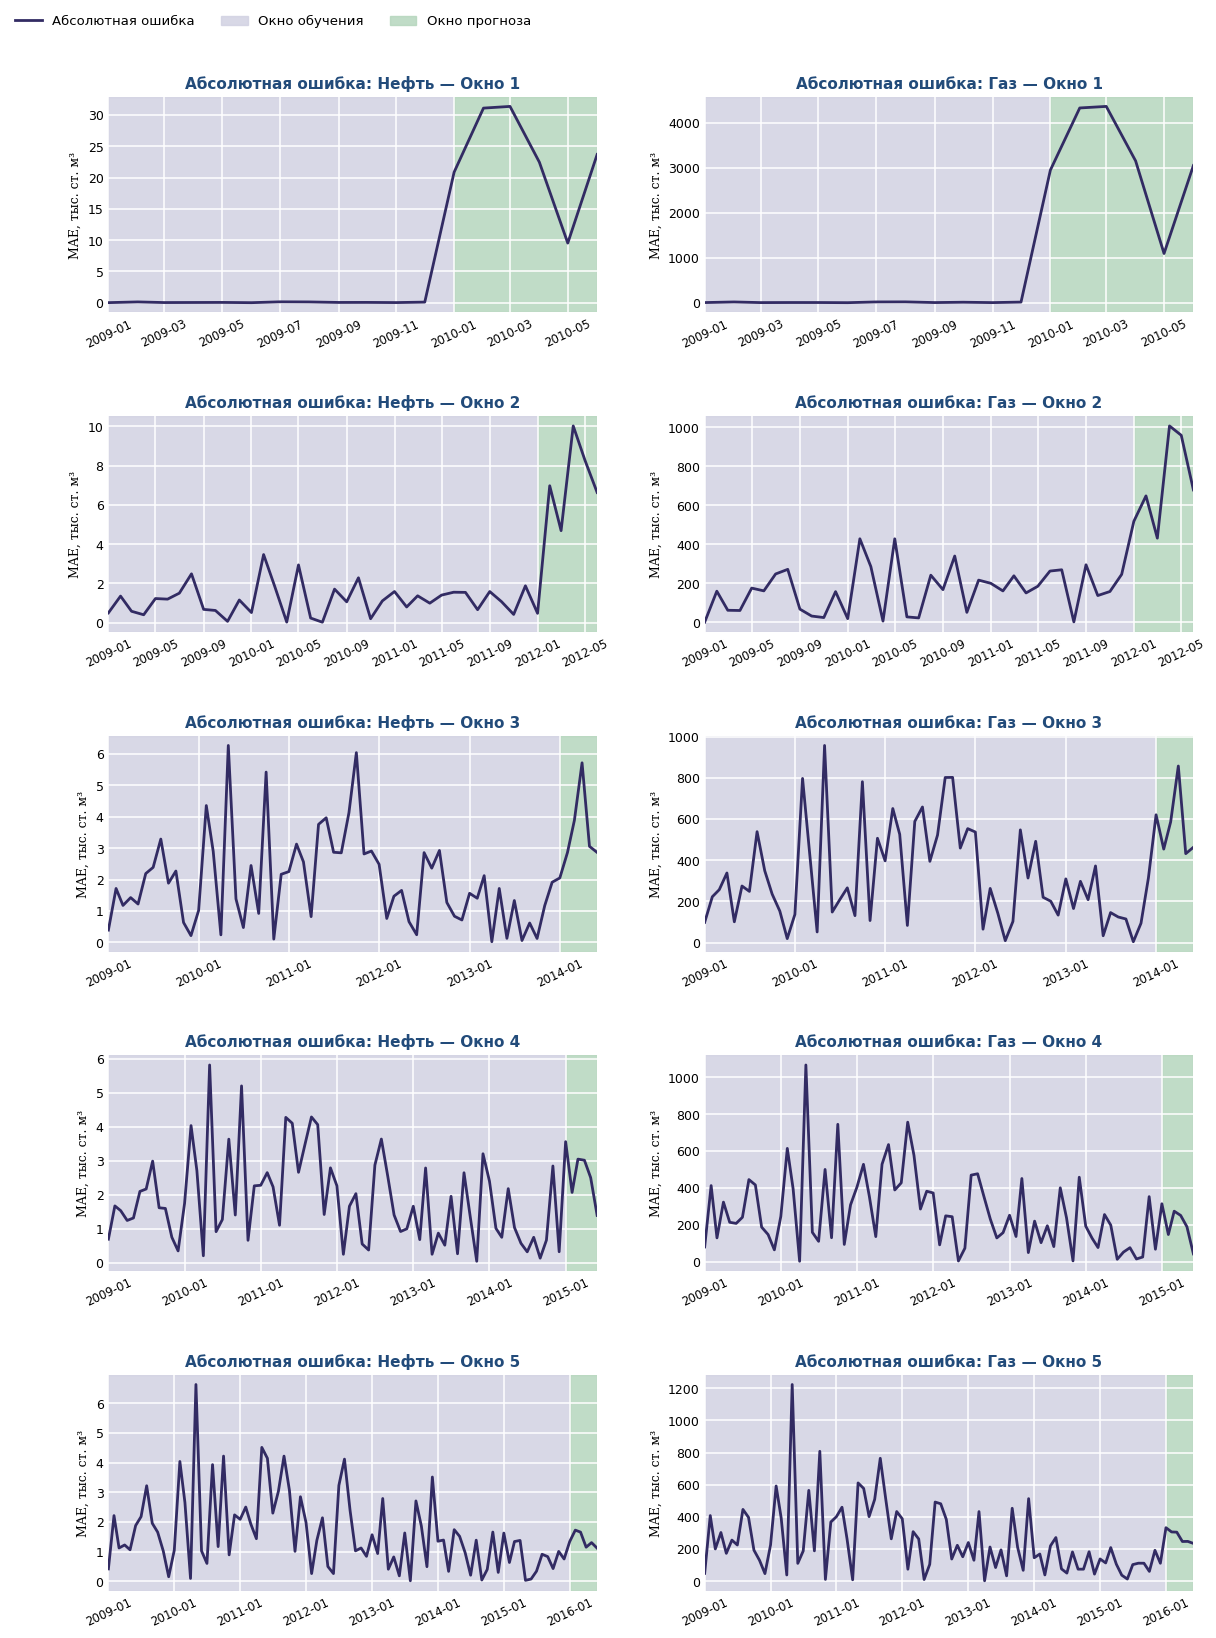

In [107]:
best_model_name = "Hybrid (Ridge + GB)"

bg_train = "#d2d2e2"     # серо-сиреневый фон окна обучения
bg_test = "#b5d6bd"      # мятно-зеленый фон окна прогноза
line_color = "#322b63"   # темно-фиолетовая линия ошибки

def plot_error_grid(error_type="abs"):
    fig, axes = plt.subplots(5, 2, figsize=(14, 18))
    fig.patch.set_facecolor("white")

    for row_idx, w in enumerate(windows):
        window_id = w["id"]
        tr = data.loc[:w["train_end"]]
        te = data.loc[w["test_start"]:w["test_end"]]
        dates_all = tr.index.append(te.index)

        for col_idx, (fluid, fluid_name) in enumerate([("BORE_OIL_VOL", "Нефть"), ("BORE_GAS_VOL", "Газ")]):
            ax = axes[row_idx, col_idx]

            y_all = np.concatenate([tr[fluid].values, te[fluid].values])
            ml_res = ml_predictions[(best_model_name, fluid, window_id)]
            pred_all = np.concatenate([ml_res["train"], ml_res["test"]])

            if error_type == "abs":
                # Абсолютная ошибка в тыс. ст. м³
                err_vals = np.abs(y_all - pred_all) / 1000.0
                ylabel_text = "MAE, тыс. ст. м³"
                title_prefix = "Абсолютная ошибка"
            else:
                # Относительная ошибка в %
                err_vals = (np.abs(y_all - pred_all) / np.where(y_all == 0, 1e-6, np.abs(y_all))) * 100.0
                ylabel_text = "MAPE, %"
                title_prefix = "Относительная ошибка"

            z_tr = ax.axvspan(tr.index.min(), te.index.min(), color=bg_train, alpha=0.85, zorder=0, label="Окно обучения")
            z_te = ax.axvspan(te.index.min(), te.index.max(), color=bg_test, alpha=0.85, zorder=0, label="Окно прогноза")

            ax.grid(True, color="white", linestyle="-", linewidth=1.1, zorder=1)
            ax.set_xlim(tr.index.min(), te.index.max())
            for spine in ax.spines.values():
                spine.set_visible(False)

            l_err, = ax.plot(dates_all, err_vals, color=line_color, linewidth=2.0, zorder=3, label=title_prefix)

            ax.set_title(f"{title_prefix}: {fluid_name} — Окно {window_id}", fontsize=11, fontweight="bold", color="#224b7a")
            ax.set_ylabel(ylabel_text, fontsize=9, fontfamily="serif")
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
            ax.tick_params(axis="x", rotation=25, labelsize=8.5, length=0)
            ax.tick_params(axis="y", labelsize=9, length=0)

    leg = fig.legend(
        handles=[l_err, z_tr, z_te],
        loc="upper left",
        bbox_to_anchor=(0.05, 0.992),
        ncol=3,
        fontsize=9.5,
        frameon=True,
        facecolor="white"
    )
    leg.get_frame().set_linewidth(0)
    plt.subplots_adjust(top=0.94, hspace=0.48, wspace=0.22)
    plt.show()

plot_error_grid(error_type="abs")

### Графики относительной ошибки

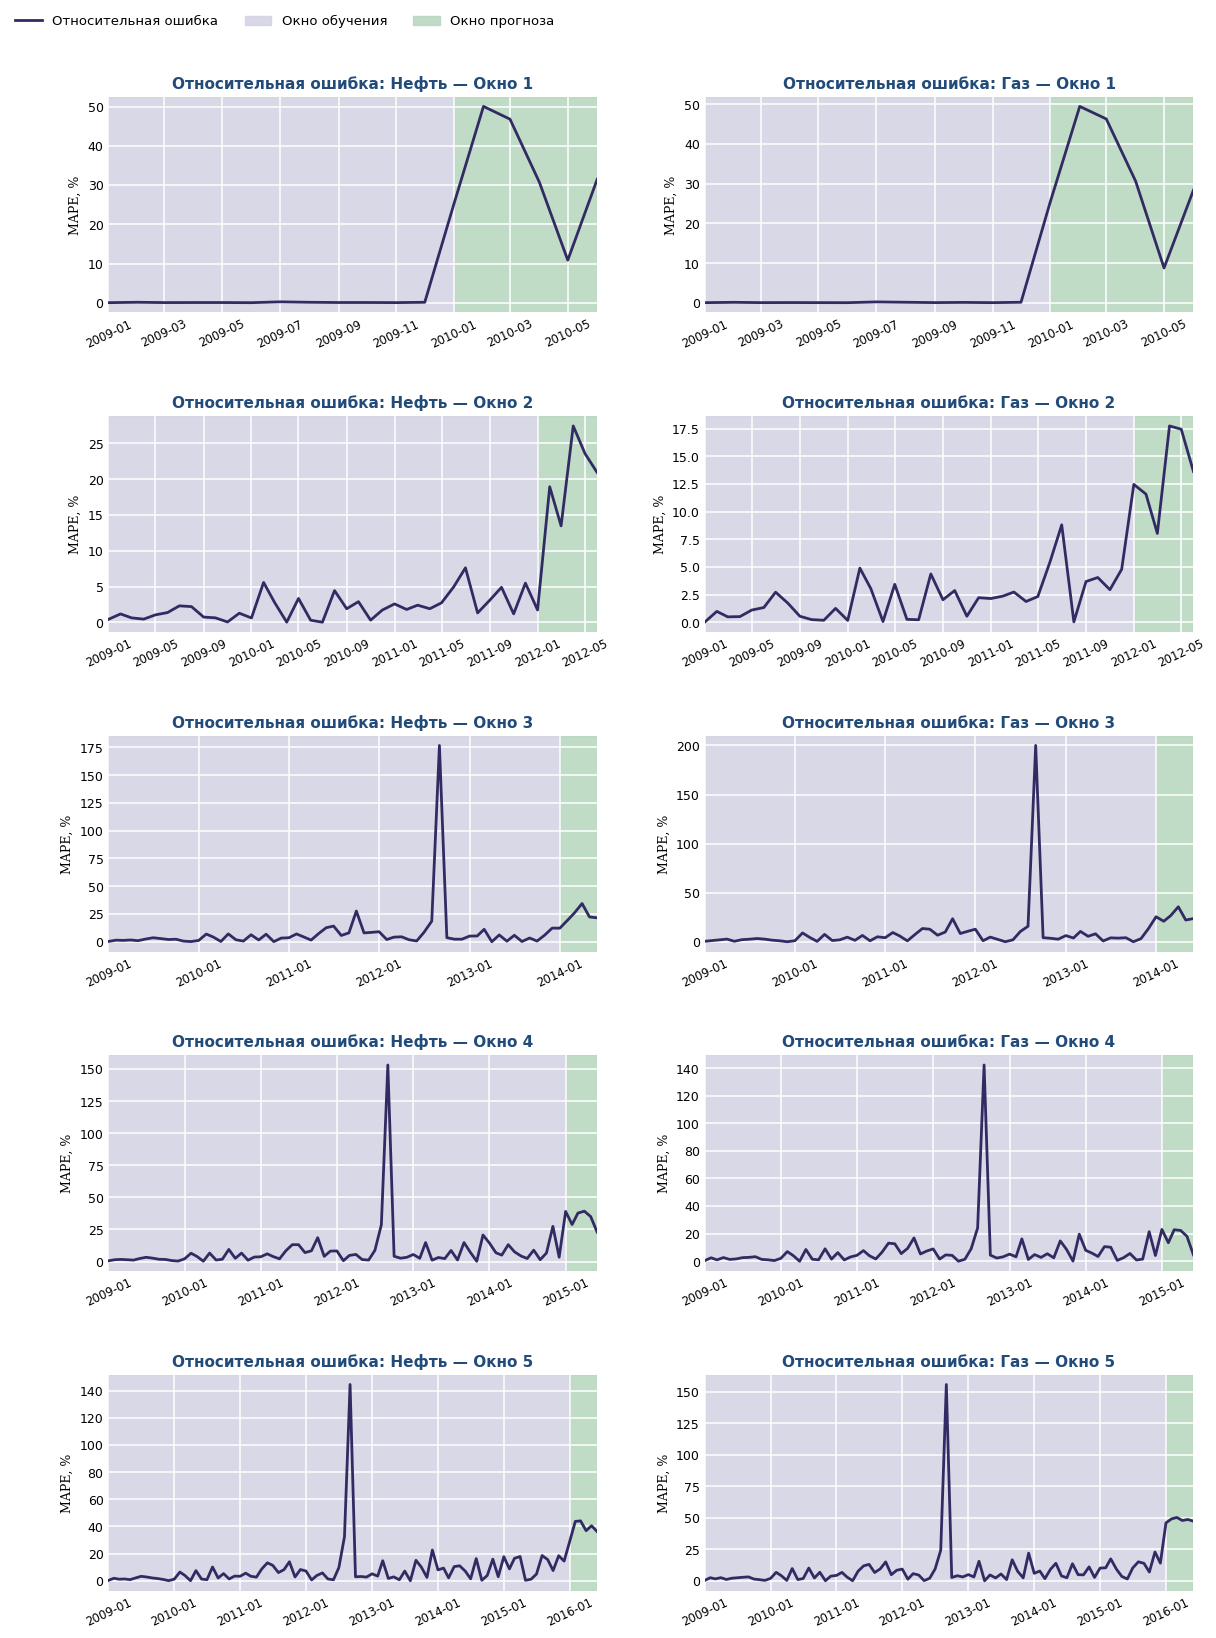

In [108]:
plot_error_grid(error_type="rel")

## Выводы:
* **Сравнение с Baseline:** Гибридная модель (Ridge + Gradient Boosting) снизила итоговую ошибку RMS_WAPE по скважине 15/9-F-14 с 45.20% до 27.66% по нефти и с 52.89% до 27.52% по газу.
* **Роль физических признаков:** Добавление эффективного дебита (oil_rate), обводненности (wc), газового фактора (gor) и давлений критически важно — при их удалении ошибка возрастает до 36.39%.
* **Регламент адаптации (дообучения):** При поступлении новых фактических замеров за очередной месяц модель переобучается по схеме расширяющегося окна (Expanding Window) — новые данные добавляются в обучающую выборку, пересчитываются лаги, скейлер и веса регрессии/бустинга.


## Мысли как можно улучшить:
1. Логарифмировать, тк данные имеют лог-нормальное распределение
2. Может убрать какие-то дуьлирующиеся признаки
3. Улучшить качество модели за счёт подбора гиперпараметров и расчёта каких-то метрик по-другому